# WLASL-100 classical ML baselines

This experiment evaluates Logistic Regression, Random Forest, linear SVM, and RBF SVM on the corrected v2 engineered features. Model selection uses signer-grouped folds within training only. Validation is descriptive; test is held out until after CV selection. Results cover only the incomplete available subset, not all 100 classes.

## 1. Imports, configuration, and paths

The experiment consumes Notebook 05 v2 raw vectors. Fold-local pipelines fit imputation, indicators, and scaling only on each fold’s training portion; the saved Notebook 05 transformers are inspected but are not reused for CV.

In [1]:
from pathlib import Path
import json, os, platform, time, warnings
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix

PROJECT_DIR=None; RANDOM_SEED=165; N_SPLITS=3; FEATURE_VERSION='wlasl100_landmark_features_v2'
def root(override=None):
    candidates=([Path(override).expanduser()] if override else [])+[Path.home()/'sign-language-recognition']
    current=Path.cwd().resolve(); candidates += [current,*current.parents]
    for p in candidates:
        if (p.resolve()/'WLASL/start_kit/WLASL_v0.3.json').is_file(): return p.resolve()
    raise FileNotFoundError('Set PROJECT_DIR to project root')
ROOT=root(PROJECT_DIR); DATA=ROOT/'data/processed/WLASL100'; V2=DATA/'features/v2'; MODELS=DATA/'models/classical/v1'; REPORTS=DATA/'reports/classical/v1'
MODELS.mkdir(parents=True,exist_ok=True); REPORTS.mkdir(parents=True,exist_ok=True)
print(ROOT, FEATURE_VERSION, sklearn.__version__)

/Users/sahilchauhan/sign-language-recognition wlasl100_landmark_features_v2 1.9.1


## 2. Load frozen metadata and v2 features

Video IDs are preserved as strings. The feature manifest is joined back to frozen metadata; signer sets must remain disjoint and each split dataset must align exactly by video ID and gloss.

In [2]:
feature_manifest=pd.read_csv(V2/'manifests/feature_manifest.csv',dtype={'video_id':str,'signer_id':str})
summary=json.loads((V2/'feature_extraction_summary.json').read_text())
if summary['feature_version']!=FEATURE_VERSION or summary['successfully_processed']!=457: raise ValueError('Unexpected v2 feature summary')
def read_frozen():
    parts=[]
    for s in ('train','val','test'):
        d=pd.read_csv(DATA/f'{s}_metadata.csv',dtype={'video_id':str,'signer_id':str}); d['video_id']=d.video_id.str.strip(); d['signer_id']=d.signer_id.astype(str); d['experimental_split']=s; parts.append(d)
    out=pd.concat(parts,ignore_index=True)
    sets={s:set(out.loc[out.experimental_split.eq(s),'signer_id']) for s in ('train','val','test')}
    assert not any(sets[a]&sets[b] for a in sets for b in sets if a<b)
    return out,sets
frozen, signer_sets=read_frozen()
usable=feature_manifest.loc[feature_manifest.status.eq('processed')].copy()
joined=usable.merge(frozen[['video_id','gloss','signer_id','experimental_split']],on='video_id',how='left',suffixes=('','_frozen'),validate='one_to_one')
for c in ('gloss','signer_id','experimental_split'): assert (joined[c].astype(str)==joined[f'{c}_frozen'].astype(str)).all()
def load_split(split):
    # Notebook 05 v2 stores signer_id as an object metadata array; these are local, schema-validated artifacts.
    with np.load(V2/'classical'/f'{split}_dataset.npz',allow_pickle=True) as z:
        data={k:z[k] for k in z.files}
    rows=usable.loc[usable.experimental_split.eq(split)].sort_values('video_id',kind='stable')
    # Dataset was written in manifest order, which is deterministic video-id order.
    assert np.array_equal(data['video_id'].astype(str),rows.video_id.to_numpy())
    assert np.array_equal(data['gloss'].astype(str),rows.gloss.to_numpy())
    assert data['X_raw'].shape[1]==86 and np.array_equal(data['feature_names'],np.array(json.loads((V2/'feature_names.json').read_text())['feature_names']))
    return data['X_raw'],data['gloss'].astype(str),rows.signer_id.to_numpy(),rows.video_id.to_numpy()
X_train,y_train,g_train,id_train=load_split('train'); X_val,y_val,g_val,id_val=load_split('val'); X_test,y_test,g_test,id_test=load_split('test')
print({'train':X_train.shape,'val':X_val.shape,'test':X_test.shape,'train_classes':len(set(y_train)),'signers':{k:len(v) for k,v in signer_sets.items()}})

{'train': (182, 86), 'val': (31, 86), 'test': (244, 86), 'train_classes': 95, 'signers': {'train': 62, 'val': 15, 'test': 20}}


## 3. Metrics and leakage-safe grouped CV

GroupKFold is used because many available classes have too few examples for a reliable stratified grouped fold. Fold reports explicitly retain missing-class information. Macro-F1 is shown both over evaluation-supported classes and over the complete training label set (zero-support classes explicitly included).

In [3]:
ALL_TRAIN_LABELS=np.array(sorted(set(y_train)))
def scores(model,X,y,training_labels=ALL_TRAIN_LABELS):
    pred=model.predict(X); classes=np.asarray(model.classes_)
    raw=model.predict_proba(X) if hasattr(model,'predict_proba') else model.decision_function(X)
    raw=np.asarray(raw); raw=raw[:,None] if raw.ndim==1 else raw
    k=min(5,raw.shape[1]); top=classes[np.argsort(raw,axis=1)[:,-k:]]
    top5=np.mean([truth in choices for truth,choices in zip(y,top)])
    eval_labels=np.unique(y); unseen=sorted(set(y)-set(classes))
    return {'accuracy':accuracy_score(y,pred),'macro_f1_eval_labels':f1_score(y,pred,labels=eval_labels,average='macro',zero_division=0),'macro_f1_train_label_set':f1_score(y,pred,labels=training_labels,average='macro',zero_division=0),'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),'balanced_accuracy':balanced_accuracy_score(y,pred),'top5_accuracy':top5,'n_samples':len(y),'n_eval_classes':len(eval_labels),'n_train_classes':len(classes),'unseen_eval_labels':len(unseen)},pred,top
def preprocess(scale=True):
    steps=[('imputer',SimpleImputer(strategy='median',add_indicator=True))]
    if scale: steps.append(('scaler',StandardScaler()))
    return steps
def estimator_specs():
    return {
      'logistic_regression':[({'C':.3,'class_weight':None}),({'C':1.0,'class_weight':'balanced'})],
      'random_forest':[({'n_estimators':250,'max_depth':None,'min_samples_leaf':1,'class_weight':None}),({'n_estimators':250,'max_depth':12,'min_samples_leaf':2,'class_weight':'balanced_subsample'})],
      'linear_svm':[({'C':.3,'class_weight':None}),({'C':1.0,'class_weight':'balanced'})],
      'rbf_svm':[({'C':1.0,'gamma':'scale','class_weight':None}),({'C':3.0,'gamma':'scale','class_weight':'balanced'})]}
def make_model(name,p):
    if name=='logistic_regression': return Pipeline(preprocess()+[('model',LogisticRegression(max_iter=3000,random_state=RANDOM_SEED,**p))])
    if name=='random_forest': return Pipeline(preprocess(False)+[('model',RandomForestClassifier(random_state=RANDOM_SEED,n_jobs=-1,**p))])
    if name=='linear_svm': return Pipeline(preprocess()+[('model',LinearSVC(random_state=RANDOM_SEED,dual='auto',max_iter=5000,**p))])
    if name=='rbf_svm': return Pipeline(preprocess()+[('model',SVC(kernel='rbf',**p))])
    raise KeyError(name)
cv=GroupKFold(n_splits=N_SPLITS); folds=list(cv.split(X_train,y_train,g_train))
fold_audit=[]
for i,(tr,va) in enumerate(folds):
    fold_audit.append({'fold':i,'train_samples':len(tr),'eval_samples':len(va),'train_signers':len(set(g_train[tr])),'eval_signers':len(set(g_train[va])),'train_classes':len(set(y_train[tr])),'eval_classes':len(set(y_train[va])),'eval_labels_absent_from_fold_train':len(set(y_train[va])-set(y_train[tr]))})
fold_audit=pd.DataFrame(fold_audit); display(fold_audit)

,fold,train_samples,eval_samples,train_signers,eval_signers,train_classes,eval_classes,eval_labels_absent_from_fold_train
0,0,100,82,8,1,65,82,30
1,1,131,51,8,1,90,46,5
2,2,133,49,2,7,92,37,3


## 4. Train-only grouped CV model selection

The small predetermined candidate grid is deliberately modest. Candidate selection ranks mean grouped-CV macro-F1 over represented evaluation labels, then accuracy; neither validation nor test metrics are used here.

In [4]:
cv_rows=[]
for name,candidates in estimator_specs().items():
    for candidate_id,params in enumerate(candidates):
        for fold,(tr,va) in enumerate(folds):
            model=make_model(name,params); start=time.perf_counter(); model.fit(X_train[tr],y_train[tr]); fit_seconds=time.perf_counter()-start
            metric,_,_=scores(model,X_train[va],y_train[va]); cv_rows.append({'model':name,'candidate_id':candidate_id,'params_json':json.dumps(params,sort_keys=True),'fold':fold,'fit_seconds':fit_seconds,**metric})
cv_detail=pd.DataFrame(cv_rows); cv_detail.to_csv(REPORTS/'grouped_cv_fold_metrics.csv',index=False)
cv_summary=cv_detail.groupby(['model','candidate_id','params_json']).agg(accuracy_mean=('accuracy','mean'),accuracy_std=('accuracy','std'),macro_f1_mean=('macro_f1_eval_labels','mean'),macro_f1_std=('macro_f1_eval_labels','std'),top5_mean=('top5_accuracy','mean'),top5_std=('top5_accuracy','std'),fit_seconds_mean=('fit_seconds','mean')).reset_index()
cv_summary=cv_summary.sort_values(['macro_f1_mean','accuracy_mean'],ascending=False); cv_summary.to_csv(REPORTS/'grouped_cv_summary.csv',index=False); display(cv_summary)
best_params={}
for name in estimator_specs():
    best=cv_summary.loc[cv_summary.model.eq(name)].iloc[0]; best_params[name]=json.loads(best.params_json)
print(best_params)

/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWa

,model,candidate_id,params_json,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,top5_mean,top5_std,fit_seconds_mean
0,linear_svm,0,"{""C"": 0.3, ""class_weight"": null}",0.070148,0.045545,0.041550,0.047580,0.160088,0.043238,0.739581
3,logistic_regression,1,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.068021,0.038665,0.038260,0.023021,0.254437,0.017391,0.123320
1,linear_svm,1,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.064406,0.007685,0.036163,0.025684,0.162559,0.036245,0.916381
4,random_forest,0,"{""class_weight"": null, ""max_depth"": null, ""min...",0.058747,0.021033,0.032425,0.027586,0.189503,0.065857,0.155852
5,random_forest,1,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.053538,0.011070,0.032015,0.012171,0.192342,0.059894,0.217473
2,logistic_regression,0,"{""C"": 0.3, ""class_weight"": null}",0.050617,0.034369,0.026109,0.022318,0.230230,0.025442,0.182834
7,rbf_svm,1,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.045408,0.011809,0.018182,0.003053,0.147360,0.022236,0.010248
6,rbf_svm,0,"{""C"": 1.0, ""class_weight"": null, ""gamma"": ""sca...",0.037545,0.024557,0.005240,0.006692,0.118561,0.074110,0.012025


{'logistic_regression': {'C': 1.0, 'class_weight': 'balanced'}, 'random_forest': {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 250}, 'linear_svm': {'C': 0.3, 'class_weight': None}, 'rbf_svm': {'C': 3.0, 'class_weight': 'balanced', 'gamma': 'scale'}}


## 5. Final fitting, descriptive validation, and held-out test

Each selected family is refit once on all 182 train examples. Validation results are descriptive because the split has only 31 sequences and 29 represented labels. Test results are recorded after CV selection without further tuning.

In [5]:
final_models={}; validation_rows=[]; test_rows=[]; prediction_rows=[]; efficiency=[]
for name,params in best_params.items():
    model=make_model(name,params); start=time.perf_counter(); model.fit(X_train,y_train); train_seconds=time.perf_counter()-start
    final_models[name]=model; joblib.dump(model,MODELS/f'{name}.joblib')
    for split,X,y,ids,collector in [('val',X_val,y_val,id_val,validation_rows),('test',X_test,y_test,id_test,test_rows)]:
        metric,pred,top=scores(model,X,y); collector.append({'model':name,'params_json':json.dumps(params,sort_keys=True),**metric})
        for vid,true,guess,ranked in zip(ids,y,pred,top): prediction_rows.append({'model':name,'split':split,'video_id':vid,'true_gloss':true,'predicted_gloss':guess,'correct':bool(true==guess),'top5_predictions':json.dumps(ranked.tolist()),'label_unseen_in_train':bool(true not in set(y_train))})
    # repeated batch inference, excluding load/plot time
    timings=[]
    for _ in range(10):
        t=time.perf_counter(); model.predict(X_test); timings.append(time.perf_counter()-t)
    file_mb=(MODELS/f'{name}.joblib').stat().st_size/1e6
    core=model.named_steps['model']; complexity=(getattr(core,'n_estimators',None) or getattr(core,'coef_',np.empty((0,))).size or getattr(core,'support_',np.empty(0)).size)
    efficiency.append({'model':name,'train_seconds':train_seconds,'test_batch_latency_mean_seconds':float(np.mean(timings)),'test_batch_latency_median_seconds':float(np.median(timings)),'latency_ms_per_sample':float(np.median(timings)*1000/len(X_test)),'model_size_mb':file_mb,'complexity_proxy':int(complexity)})
validation=pd.DataFrame(validation_rows); test=pd.DataFrame(test_rows); predictions=pd.DataFrame(prediction_rows); efficiency=pd.DataFrame(efficiency)
validation.to_csv(REPORTS/'validation_metrics_descriptive.csv',index=False); test.to_csv(REPORTS/'test_metrics_held_out.csv',index=False); predictions.to_csv(REPORTS/'predictions.csv',index=False); efficiency.to_csv(REPORTS/'efficiency.csv',index=False)
display(validation); display(test); display(efficiency)

/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:811: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could r

,model,params_json,accuracy,macro_f1_eval_labels,macro_f1_train_label_set,weighted_f1,balanced_accuracy,top5_accuracy,n_samples,n_eval_classes,n_train_classes,unseen_eval_labels
0,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.129032,0.100000,0.030526,0.109677,0.120690,0.290323,31,29,95,0
1,random_forest,"{""class_weight"": null, ""max_depth"": null, ""min...",0.129032,0.103448,0.031579,0.107527,0.120690,0.225806,31,29,95,0
2,linear_svm,"{""C"": 0.3, ""class_weight"": null}",0.096774,0.071264,0.021754,0.079570,0.086207,0.225806,31,29,95,0
3,rbf_svm,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.000000,0.000000,0.000000,0.000000,0.000000,0.161290,31,29,95,0


,model,params_json,accuracy,macro_f1_eval_labels,macro_f1_train_label_set,weighted_f1,balanced_accuracy,top5_accuracy,n_samples,n_eval_classes,n_train_classes,unseen_eval_labels
0,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.135246,0.104498,0.106698,0.095536,0.153780,0.315574,244,97,95,5
1,random_forest,"{""class_weight"": null, ""max_depth"": null, ""min...",0.131148,0.079870,0.081551,0.089799,0.137285,0.307377,244,97,95,5
2,linear_svm,"{""C"": 0.3, ""class_weight"": null}",0.098361,0.058179,0.059404,0.066203,0.105670,0.250000,244,97,95,5
3,rbf_svm,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.081967,0.061450,0.062744,0.065978,0.080584,0.233607,244,97,95,5


,model,train_seconds,test_batch_latency_mean_seconds,test_batch_latency_median_seconds,latency_ms_per_sample,model_size_mb,complexity_proxy
0,logistic_regression,0.226118,0.001845,0.000966,0.003959,0.069973,14820
1,random_forest,0.302949,0.025640,0.026577,0.108921,40.204074,250
2,linear_svm,0.325488,0.000403,0.000393,0.001610,0.129501,14820
3,rbf_svm,0.016372,0.009014,0.007168,0.029379,0.620941,182


## 6. Error analysis and plots

The selected model is the family with the strongest training-only CV macro-F1. Test error analyses exclude labels absent from its training label set from claims about model confusion, while retaining their count in the metrics table.

/Users/sahilchauhan/sign-language-recognition/.venv312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,precision,recall,f1-score,support
accident,0.0,0.0,0.0,1.0
africa,0.0,0.0,0.0,4.0
all,0.0,0.0,0.0,4.0
apple,0.0,0.0,0.0,1.0
basketball,0.0,0.0,0.0,1.0


,true_gloss,predicted_gloss,count
0,need,white,4
1,forget,brown,4
2,cook,book,3
3,kiss,book,3
4,but,white,3
5,family,book,3
6,yes,white,2
7,orange,brown,2
8,study,brown,2
9,secretary,hat,2


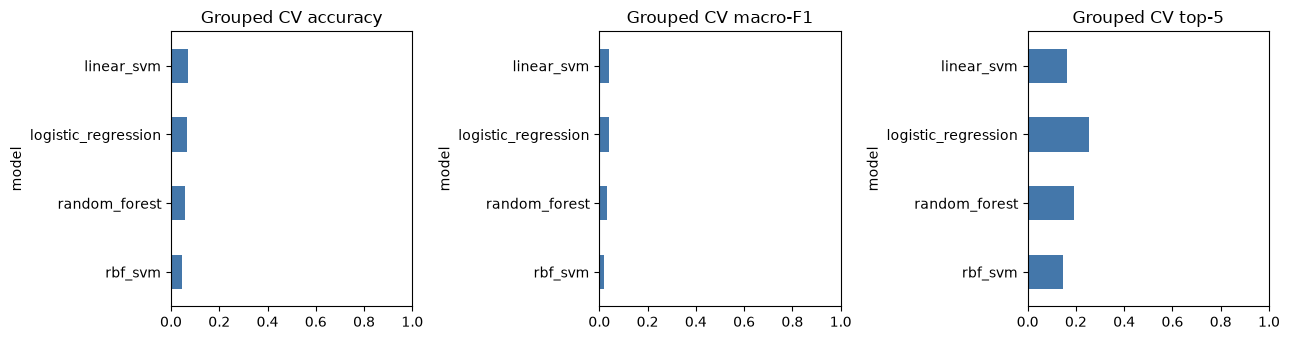

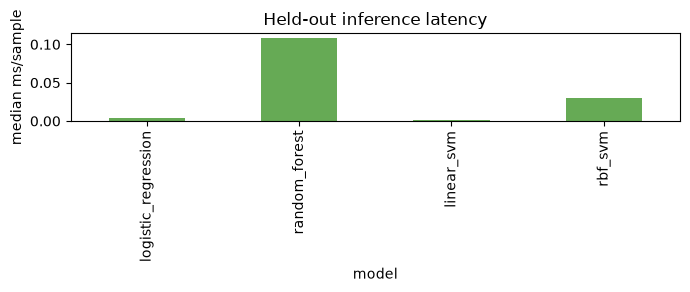

In [6]:
selected=cv_summary.iloc[0].model; model=final_models[selected]; metrics,pred,top=scores(model,X_test,y_test)
known=np.array([label in set(y_train) for label in y_test]); known_labels=np.array(sorted(set(y_test[known])))
cm=confusion_matrix(y_test[known],pred[known],labels=known_labels) if known.any() else np.empty((0,0),int)
np.save(REPORTS/'selected_model_confusion_matrix.npy',cm); pd.DataFrame(cm,index=known_labels,columns=known_labels).to_csv(REPORTS/'selected_model_confusion_matrix.csv')
report=pd.DataFrame(classification_report(y_test[known],pred[known],labels=known_labels,output_dict=True,zero_division=0)).T if known.any() else pd.DataFrame()
report.to_csv(REPORTS/'selected_model_per_class_report.csv')
wrong=predictions.loc[(predictions.model.eq(selected))&(predictions.split.eq('test'))&(~predictions.correct)].copy(); pairs=wrong.groupby(['true_gloss','predicted_gloss']).size().sort_values(ascending=False).rename('count').reset_index(); pairs.to_csv(REPORTS/'frequent_confusions.csv',index=False)
display(report.head()); display(pairs.head(10))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
plot=cv_summary.groupby('model')[['accuracy_mean','macro_f1_mean','top5_mean']].max().sort_values('macro_f1_mean')
for ax,col,title in zip(axes,['accuracy_mean','macro_f1_mean','top5_mean'],['Grouped CV accuracy','Grouped CV macro-F1','Grouped CV top-5']): plot[col].plot.barh(ax=ax,color='#4477AA'); ax.set_title(title); ax.set_xlim(0,1)
plt.tight_layout(); plt.savefig(REPORTS/'cv_model_comparison.png',dpi=160); plt.show()
fig,ax=plt.subplots(figsize=(7,3)); efficiency.set_index('model')['latency_ms_per_sample'].plot.bar(ax=ax,color='#66AA55'); ax.set_ylabel('median ms/sample'); ax.set_title('Held-out inference latency'); plt.tight_layout(); plt.savefig(REPORTS/'inference_latency.png',dpi=160); plt.show()

## 7. Save experiment record and research interpretation

Results are baseline estimates subject to severe availability imbalance and class sparsity. In particular, grouped folds and validation/test sets do not contain every available training class. No conclusion about WLASL-300/2000 scaling follows from this notebook.

In [7]:
config={'feature_version':FEATURE_VERSION,'random_seed':RANDOM_SEED,'cv':'GroupKFold(3), grouped by frozen train signer IDs','models':best_params,'software':{'python':platform.python_version(),'sklearn':sklearn.__version__},'train_rows':len(X_train),'val_rows':len(X_val),'test_rows':len(X_test),'signer_intersections':0,'selection_rule':'highest grouped-CV macro-F1 over represented evaluation labels, then accuracy','validation_note':'descriptive only; no validation hyperparameter tuning','test_note':'evaluated after CV selection without tuning'}
(REPORTS/'experiment_config.json').write_text(json.dumps(config,indent=2));
summary={'selected_by_training_only_cv':selected,'cv_best_row':cv_summary.iloc[0].to_dict(),'validation_results':validation.to_dict('records'),'test_results':test.to_dict('records'),'limitations':['457 available sequences from 2,038 metadata instances','31 validation sequences across 29 represented labels','many classes have sparse train support; grouped folds can lack labels'],'artifacts':{'models':str(MODELS),'reports':str(REPORTS)}}
(REPORTS/'experiment_summary.json').write_text(json.dumps(summary,indent=2)); print(json.dumps(summary,indent=2))

{
  "selected_by_training_only_cv": "linear_svm",
  "cv_best_row": {
    "model": "linear_svm",
    "candidate_id": 0,
    "params_json": "{\"C\": 0.3, \"class_weight\": null}",
    "accuracy_mean": 0.07014838455707485,
    "accuracy_std": 0.045545422797702205,
    "macro_f1_mean": 0.04155006254688121,
    "macro_f1_std": 0.04758016443685566,
    "top5_mean": 0.1600884256141481,
    "top5_std": 0.043238178088240105,
    "fit_seconds_mean": 0.7395808613315845
  },
  "validation_results": [
    {
      "model": "logistic_regression",
      "params_json": "{\"C\": 1.0, \"class_weight\": \"balanced\"}",
      "accuracy": 0.12903225806451613,
      "macro_f1_eval_labels": 0.09999999999999999,
      "macro_f1_train_label_set": 0.030526315789473683,
      "weighted_f1": 0.10967741935483871,
      "balanced_accuracy": 0.1206896551724138,
      "top5_accuracy": 0.2903225806451613,
      "n_samples": 31,
      "n_eval_classes": 29,
      "n_train_classes": 95,
      "unseen_eval_labels": 0
    }